In [6]:
pip install tensorflow numpy pandas matplotlib scikit-learn

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.1-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached m


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Scripts\python.exe -m pip install --upgrade pip


C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.3150 - loss: 1.9096 - val_accuracy: 0.3548 - val_loss: 1.7818
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.3969 - loss: 1.6944 - val_accuracy: 0.4132 - val_loss: 1.6738
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4235 - loss: 1.6146 - val_accuracy: 0.4012 - val_loss: 1.6639
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4466 - loss: 1.5504 - val_accuracy: 0.4248 - val_loss: 1.6230
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4626 - loss: 1.5068 - val_accuracy: 0.4626 - val_loss: 1.5137
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4728 - loss: 1.4784 - val_accuracy: 0.4754 - val_loss: 1.4824
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4877 - loss: 1.4403 - val_accuracy: 0.4548 - val_loss: 1.5223
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4963 - loss: 1.4114 - val_accu

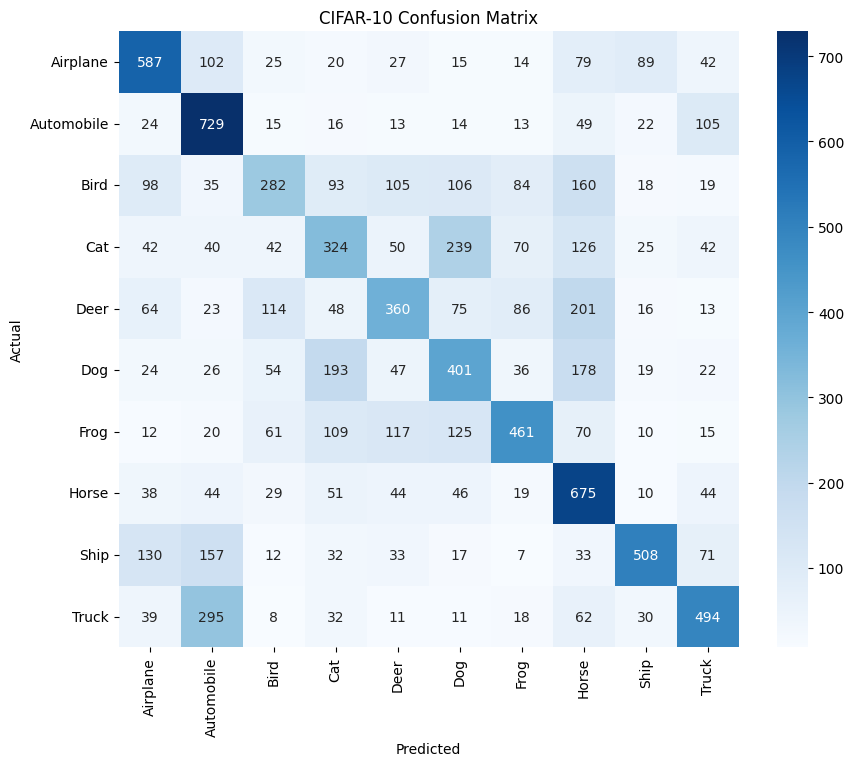

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4821 - loss: 1.4548
Test Accuracy: 0.4821000099182129


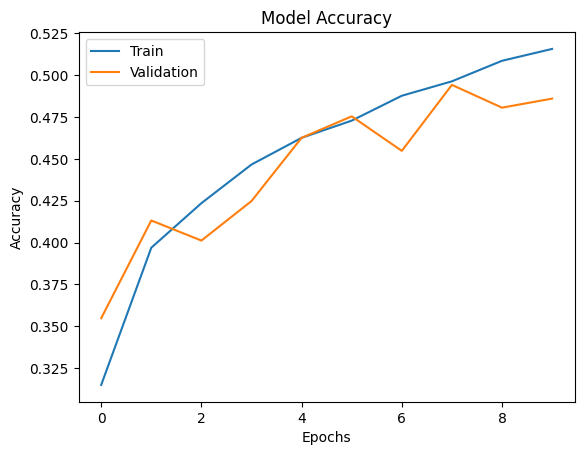

In [7]:

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 2. Load dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# 3. Class names
classes = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
           'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

# 4. Convert labels into 1D arrays
y_train = y_train.flatten()
y_test = y_test.flatten()

# 5. Normalize and reshape images
X_train = X_train.reshape(-1, 3072) / 255.0
X_test = X_test.reshape(-1, 3072) / 255.0

# 6. Build FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation="relu",
                          input_shape=(3072,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 7. Compile model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 8. Train model
history = model.fit(X_train, y_train,
                    epochs=10, batch_size=128,
                    validation_split=0.1)

# 9. Predict test images
y_pred = np.argmax(model.predict(X_test), axis=1)

# 10. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CIFAR-10 Confusion Matrix")
plt.show()

# 11. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# 12. Plot accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()


C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.8269 - loss: 0.4893 - val_accuracy: 0.8440 - val_loss: 0.4350
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8685 - loss: 0.3582 - val_accuracy: 0.8588 - val_loss: 0.3765
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8809 - loss: 0.3221 - val_accuracy: 0.8813 - val_loss: 0.3344
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8890 - loss: 0.2987 - val_accuracy: 0.8847 - val_loss: 0.3202
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8963 - loss: 0.2802 - val_accuracy: 0.8757 - val_loss: 0.3430
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9028 - loss: 0.2639 - val_accuracy: 0.8862 - val_loss: 0.3208
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9080 - loss: 0.2490 - val_accuracy: 0.8903 - val_loss: 0.3133
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9108 - loss: 0.2394 - val_accu

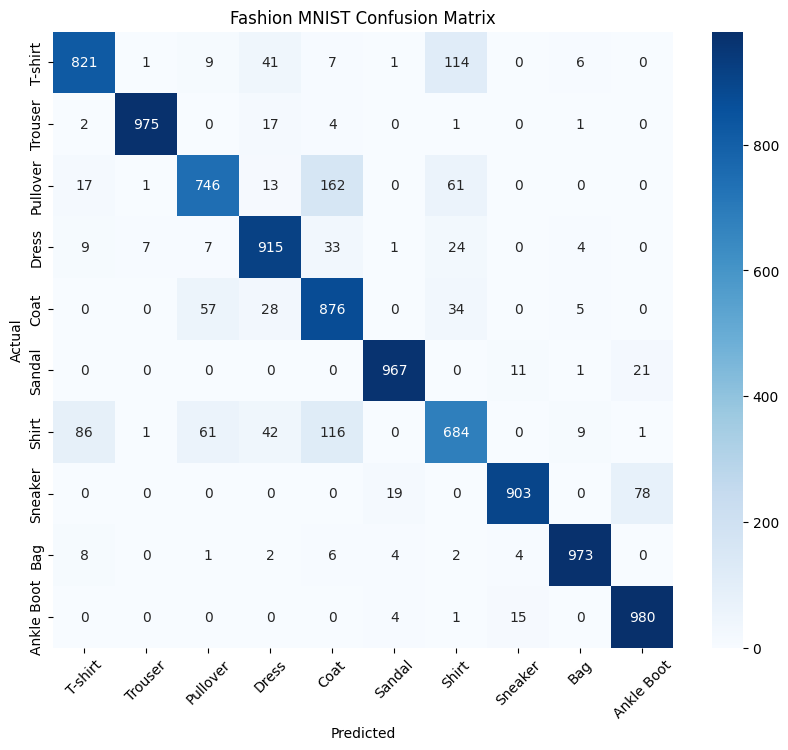

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8840 - loss: 0.3449
Test Accuracy: 0.8840000033378601


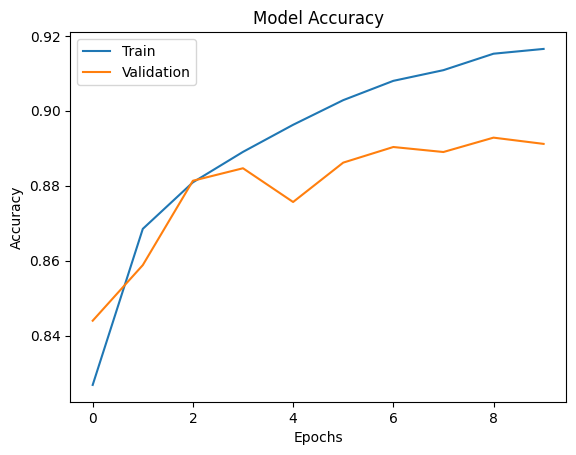

In [6]:

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 2. Load dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# 3. Class names
classes = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot']

# 4. Normalize and reshape images
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

# 5. Build FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation="relu",
                          input_shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 6. Compile model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 7. Train model
history = model.fit(X_train, y_train,
                    epochs=10, batch_size=128,
                    validation_split=0.1)

# 8. Predict test images
y_pred = np.argmax(model.predict(X_test), axis=1)

# 9. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fashion MNIST Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

# 10. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# 11. Plot accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()


C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9301 - loss: 0.2411 - val_accuracy: 0.9715 - val_loss: 0.0966
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9730 - loss: 0.0893 - val_accuracy: 0.9750 - val_loss: 0.0784
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9825 - loss: 0.0564 - val_accuracy: 0.9808 - val_loss: 0.0718
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9875 - loss: 0.0375 - val_accuracy: 0.9767 - val_loss: 0.0800
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9908 - loss: 0.0280 - val_accuracy: 0.9780 - val_loss: 0.0786
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9926 - loss: 0.0223 - val_accuracy: 0.9783 - val_loss: 0.0788
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9941 - loss: 0.0185 - val_accuracy: 0.9800 - val_loss: 0.0817
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9942 - loss: 0.0170 - val_accurac

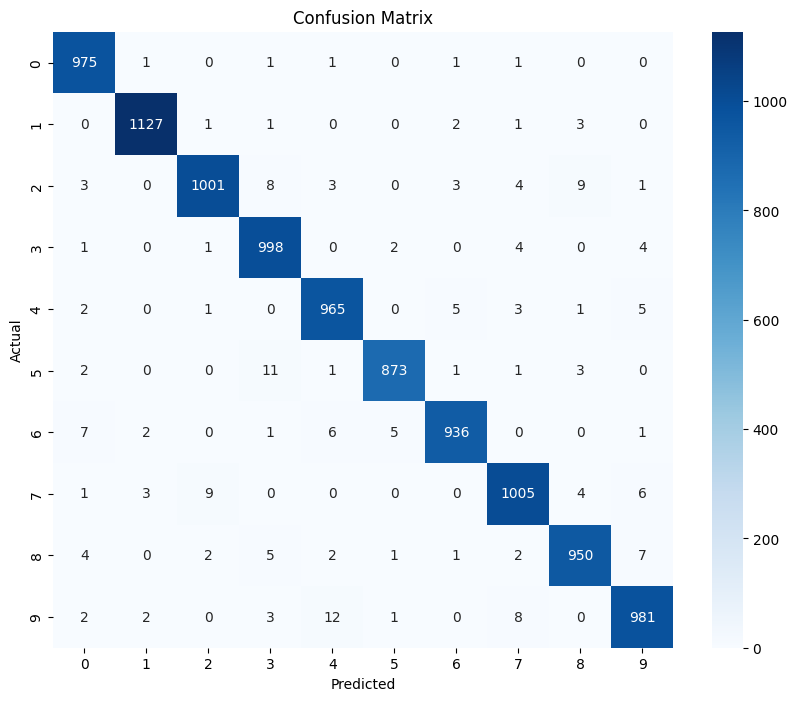

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9811 - loss: 0.0719
Test Accuracy: 0.9811000227928162


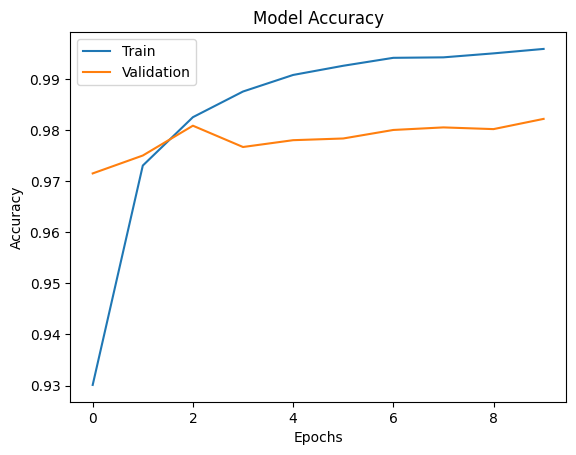

In [5]:


# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 2. Load dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# 3. Normalize and reshape images
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

# 4. Build FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation="relu",
                          input_shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 5. Compile model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 6. Train model
history = model.fit(X_train, y_train,
                    epochs=10, batch_size=128,
                    validation_split=0.1)

# 7. Predict test images
y_pred = np.argmax(model.predict(X_test), axis=1)

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 9. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# 10. Plot accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()


C:\Users\Sejal patil\OneDrive\Documents\MachineLearning\aiml_env\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.3859 - loss: 2.0332 - val_accuracy: 0.5025 - val_loss: 1.5300
Epoch 2/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6524 - loss: 1.1097 - val_accuracy: 0.6318 - val_loss: 1.0093
Epoch 3/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7711 - loss: 0.7469 - val_accuracy: 0.7804 - val_loss: 0.6656
Epoch 4/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8500 - loss: 0.5001 - val_accuracy: 0.8718 - val_loss: 0.4249
Epoch 5/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8963 - loss: 0.3591 - val_accuracy: 0.8565 - val_loss: 0.4551
Epoch 6/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9398 - loss: 0.2363 - val_accuracy: 0.9505 - val_loss: 0.1948
Epoch 7/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9576 - loss: 0.1752 - val_accuracy: 0.9541 - val_loss: 0.1522
Epoch 8/15
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9728 - loss: 0.1205 - val_accu

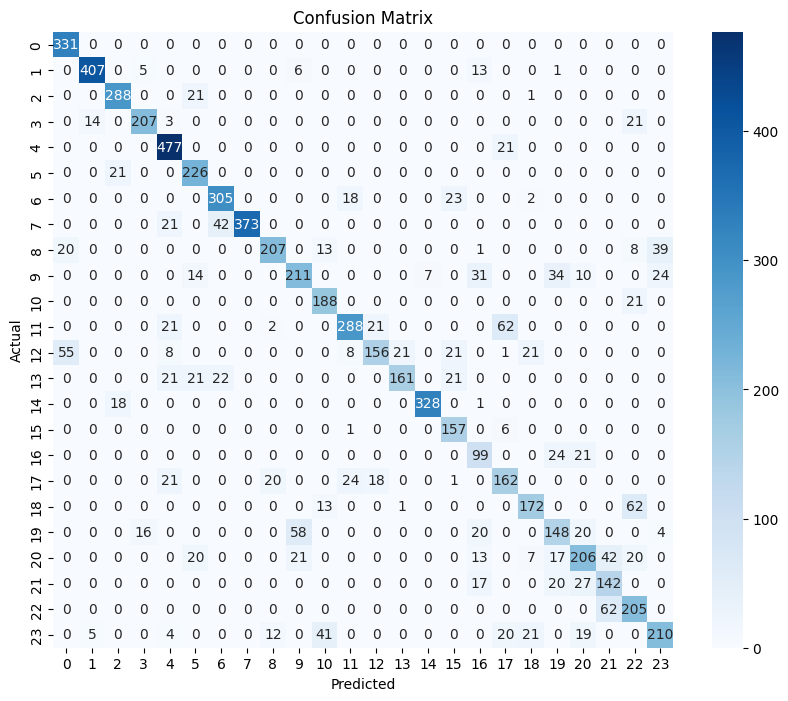

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7883 - loss: 0.9365
Test Accuracy: 0.7883435487747192


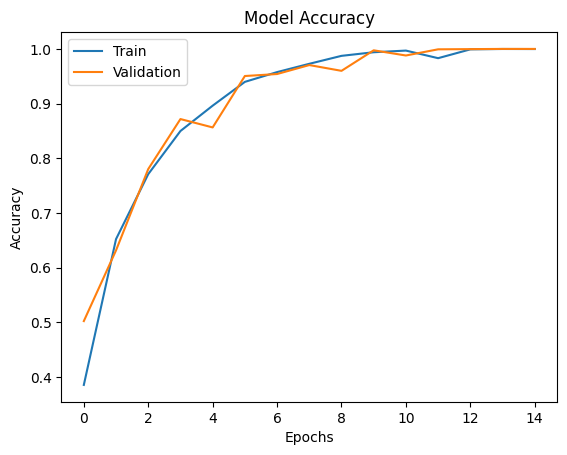

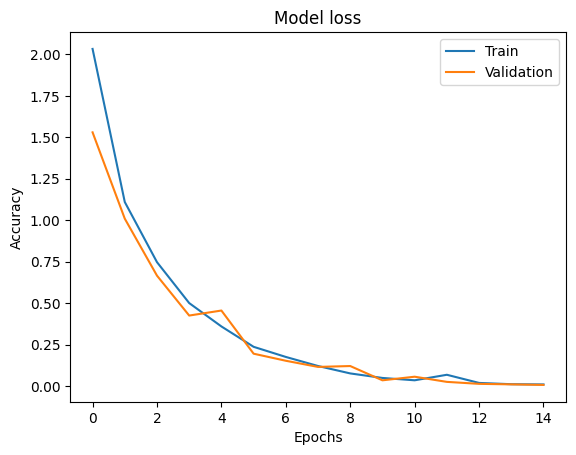

In [4]:

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 2. Load dataset
train = pd.read_csv("sign_mnist_train.csv")
test = pd.read_csv("sign_mnist_test.csv")

X_train = train.drop("label", axis=1).values / 255.0
y_train = train["label"].values

X_test = test.drop("label", axis=1).values / 255.0
y_test = test["label"].values

# 3. Convert labels into consecutive numbers
labels = sorted(train["label"].unique())
label_map = {label: i for i, label in enumerate(labels)}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

# 4. Build FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(512, activation="relu",
                          input_shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(24, activation="softmax")
])

# 5. Compile model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 6. Train model
history = model.fit(X_train, y_train,
                    epochs=15, batch_size=128,
                    validation_split=0.1)

# 7. Predict test images
y_pred = np.argmax(model.predict(X_test), axis=1)

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 9. Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

# 10. Plot accuracy
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Model loss")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()